# Guava Image Translation with VQ-VAE

A paired wrapped-to-unwrapped guava image experiment using a **Vector-Quantized Variational Autoencoder (VQ-VAE)** implemented in PyTorch.

This notebook includes **saved outputs from the original experiment**, including training logs, comparison plots, and evaluation metrics. They are not newly reproduced results. Execute cells in order to train and calculate new results.

Training: 10 paired examples. Validation: 10 paired examples. Dataset photographs collected by the project author.


In [1]:
from __future__ import print_function

import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import torchvision.transforms as transforms
from torchvision.utils import make_grid

from PIL import Image, ImageOps
from six.moves import xrange
import umap

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: cpu


## Running the notebook

Clone this repository or download it with its `dataset/` folder, then run cells in order. The notebook uses local relative paths and does not require Google Drive mounting.


In [2]:
# Dataset included in this repository; run from the repository root.
base_dataset_path = "dataset"

train_wrapped = os.path.join(base_dataset_path, "train", "wrapped")
train_unwrapped = os.path.join(base_dataset_path, "train", "unwrapped")
val_wrapped = os.path.join(base_dataset_path, "val", "wrapped")
val_unwrapped = os.path.join(base_dataset_path, "val", "unwrapped")

for folder in (train_wrapped, train_unwrapped, val_wrapped, val_unwrapped):
    if not os.path.isdir(folder):
        raise FileNotFoundError(f"Dataset folder not found: {folder}. Run from repository root.")
print("Dataset folders found:", base_dataset_path)


Dataset folders found: dataset


In [3]:
class GuavaPairedDataset(Dataset):
    def __init__(self, wrapped_dir, unwrapped_dir, crop_top_ratio=0.15):
        self.wrapped_dir = wrapped_dir
        self.unwrapped_dir = unwrapped_dir
        self.crop_top_ratio = crop_top_ratio

        self.images = sorted([f for f in os.listdir(wrapped_dir) if not f.startswith('.')])

        self.transform = transforms.Compose([
            transforms.Resize((32, 32)),
            transforms.ToTensor(),
            transforms.Normalize((0.5, 0.5, 0.5), (1.0, 1.0, 1.0))
        ])

    def _load(self, path):
        img = Image.open(path).convert("RGB")

        # 🔄 FIX ROTATION
        img = ImageOps.exif_transpose(img)

        # ✂️ REMOVE SCALE (TOP)
        crop_top = int(img.height * self.crop_top_ratio)
        img = img.crop((0, crop_top, img.width, img.height))

        return self.transform(img)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        name = self.images[idx]
        wrapped = self._load(os.path.join(self.wrapped_dir, name))
        unwrapped = self._load(os.path.join(self.unwrapped_dir, name))
        return wrapped, unwrapped


In [4]:
batch_size = 8

train_data = GuavaPairedDataset(train_wrapped, train_unwrapped)
val_data   = GuavaPairedDataset(val_wrapped, val_unwrapped)

train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_data, batch_size=batch_size, shuffle=False)

print("Train samples:", len(train_data))
print("Val samples:", len(val_data))


Train samples: 10
Val samples: 10


In [5]:
temp_loader = DataLoader(train_data, batch_size=256, shuffle=True)
_, unwrapped_batch = next(iter(temp_loader))
data_variance = np.var(unwrapped_batch.numpy())

print("Data variance:", data_variance)


Data variance: 0.03593905


In [6]:
# =========================
# Vector Quantizer
# =========================
class VectorQuantizer(nn.Module):
    def __init__(self, num_embeddings, embedding_dim, commitment_cost):
        super(VectorQuantizer, self).__init__()

        self.embedding_dim = embedding_dim
        self.num_embeddings = num_embeddings
        self.commitment_cost = commitment_cost

        self.embedding = nn.Embedding(self.num_embeddings, self.embedding_dim)
        self.embedding.weight.data.uniform_(-1/self.num_embeddings, 1/self.num_embeddings)

    def forward(self, inputs):
        # BCHW -> BHWC
        inputs = inputs.permute(0, 2, 3, 1).contiguous()
        input_shape = inputs.shape

        flat_input = inputs.view(-1, self.embedding_dim)

        distances = (
            torch.sum(flat_input ** 2, dim=1, keepdim=True)
            + torch.sum(self.embedding.weight ** 2, dim=1)
            - 2 * torch.matmul(flat_input, self.embedding.weight.t())
        )

        encoding_indices = torch.argmin(distances, dim=1).unsqueeze(1)
        encodings = torch.zeros(encoding_indices.shape[0], self.num_embeddings, device=inputs.device)
        encodings.scatter_(1, encoding_indices, 1)

        quantized = torch.matmul(encodings, self.embedding.weight).view(input_shape)

        e_latent_loss = F.mse_loss(quantized.detach(), inputs)
        q_latent_loss = F.mse_loss(quantized, inputs.detach())
        loss = q_latent_loss + self.commitment_cost * e_latent_loss

        quantized = inputs + (quantized - inputs).detach()

        avg_probs = torch.mean(encodings, dim=0)
        perplexity = torch.exp(-torch.sum(avg_probs * torch.log(avg_probs + 1e-10)))

        # BHWC -> BCHW
        quantized = quantized.permute(0, 3, 1, 2).contiguous()

        return loss, quantized, perplexity


# =========================
# Residual Blocks
# =========================
class Residual(nn.Module):
    def __init__(self, in_channels, num_hiddens, num_residual_hiddens):
        super(Residual, self).__init__()
        self.block = nn.Sequential(
            nn.ReLU(True),
            nn.Conv2d(in_channels, num_residual_hiddens, kernel_size=3, stride=1, padding=1, bias=False),
            nn.ReLU(True),
            nn.Conv2d(num_residual_hiddens, num_hiddens, kernel_size=1, stride=1, bias=False)
        )

    def forward(self, x):
        return x + self.block(x)


class ResidualStack(nn.Module):
    def __init__(self, in_channels, num_hiddens, num_residual_layers, num_residual_hiddens):
        super(ResidualStack, self).__init__()
        self.layers = nn.ModuleList([
            Residual(in_channels, num_hiddens, num_residual_hiddens)
            for _ in range(num_residual_layers)
        ])

    def forward(self, x):
        for layer in self.layers:
            x = layer(x)
        return F.relu(x)


# =========================
# Encoder
# =========================
class Encoder(nn.Module):
    def __init__(self, in_channels, num_hiddens, num_residual_layers, num_residual_hiddens):
        super(Encoder, self).__init__()

        self.conv1 = nn.Conv2d(in_channels, num_hiddens // 2, kernel_size=4, stride=2, padding=1)
        self.conv2 = nn.Conv2d(num_hiddens // 2, num_hiddens, kernel_size=4, stride=2, padding=1)
        self.conv3 = nn.Conv2d(num_hiddens, num_hiddens, kernel_size=3, stride=1, padding=1)

        self.res_stack = ResidualStack(
            in_channels=num_hiddens,
            num_hiddens=num_hiddens,
            num_residual_layers=num_residual_layers,
            num_residual_hiddens=num_residual_hiddens
        )

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = self.conv3(x)
        return self.res_stack(x)


# =========================
# Decoder
# =========================
class Decoder(nn.Module):
    def __init__(self, in_channels, num_hiddens, num_residual_layers, num_residual_hiddens):
        super(Decoder, self).__init__()

        self.conv1 = nn.Conv2d(in_channels, num_hiddens, kernel_size=3, stride=1, padding=1)

        self.res_stack = ResidualStack(
            in_channels=num_hiddens,
            num_hiddens=num_hiddens,
            num_residual_layers=num_residual_layers,
            num_residual_hiddens=num_residual_hiddens
        )

        self.deconv1 = nn.ConvTranspose2d(num_hiddens, num_hiddens // 2, kernel_size=4, stride=2, padding=1)
        self.deconv2 = nn.ConvTranspose2d(num_hiddens // 2, 3, kernel_size=4, stride=2, padding=1)

    def forward(self, x):
        x = self.conv1(x)
        x = self.res_stack(x)
        x = F.relu(self.deconv1(x))
        return self.deconv2(x)


# =========================
# Full VQ-VAE Model
# =========================
class Model(nn.Module):
    def __init__(self, num_hiddens, num_residual_layers, num_residual_hiddens,
                 num_embeddings, embedding_dim, commitment_cost, decay=0):
        super(Model, self).__init__()

        self.encoder = Encoder(3, num_hiddens, num_residual_layers, num_residual_hiddens)
        self.pre_vq_conv = nn.Conv2d(num_hiddens, embedding_dim, kernel_size=1)

        if decay > 0:
            self.vq = VectorQuantizer(num_embeddings, embedding_dim, commitment_cost)
        else:
            self.vq = VectorQuantizer(num_embeddings, embedding_dim, commitment_cost)

        self.decoder = Decoder(embedding_dim, num_hiddens, num_residual_layers, num_residual_hiddens)

    def forward(self, x):
        z = self.encoder(x)
        z = self.pre_vq_conv(z)
        vq_loss, quantized, perplexity = self.vq(z)
        recon = self.decoder(quantized)
        return vq_loss, recon, perplexity


In [7]:
model = Model(
    num_hiddens=32,
    num_residual_layers=2,
    num_residual_hiddens=16,
    num_embeddings=64,
    embedding_dim=32,
    commitment_cost=0.25,
    decay=0.99
).to(device)

optimizer = optim.Adam(model.parameters(), lr=1e-3)

model.train()
recon_log = []
perplex_log = []

for step in range(200):
    wrapped, unwrapped = next(iter(train_loader))
    wrapped = wrapped.to(device)
    unwrapped = unwrapped.to(device)

    optimizer.zero_grad()
    vq_loss, recon, perplexity = model(wrapped)

    recon_error = F.mse_loss(recon, unwrapped) / data_variance
    loss = recon_error + vq_loss
    loss.backward()
    optimizer.step()

    recon_log.append(recon_error.item())
    perplex_log.append(perplexity.item())

    if (step + 1) % 50 == 0:
        print(f"{step+1} | Recon: {np.mean(recon_log[-50:]):.4f} | Perplexity: {np.mean(perplex_log[-50:]):.2f}")


50 | Recon: 2.2787 | Perplexity: 1.00


KeyboardInterrupt: 

In [ ]:
def denormalize(img):
    img = img + 0.5
    return torch.clamp(img, 0.0, 1.0)

def show_batch(title, images):
    images = denormalize(images.cpu())
    grid = make_grid(images, nrow=4)
    npimg = grid.numpy()
    plt.figure(figsize=(6,6))
    plt.title(title)
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.axis("off")
    plt.show()


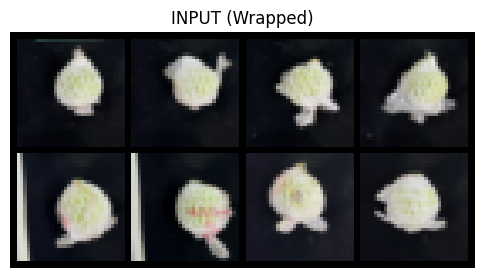

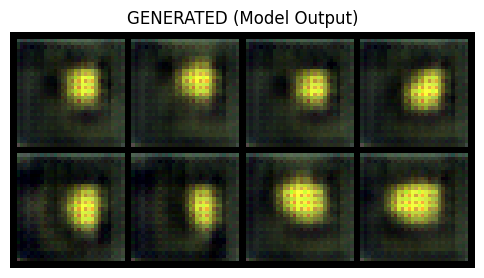

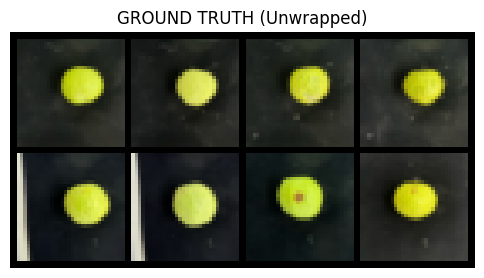

In [ ]:
model.eval()

wrapped, unwrapped = next(iter(val_loader))
wrapped = wrapped.to(device)
unwrapped = unwrapped.to(device)

with torch.no_grad():
    _, recon, _ = model(wrapped)

show_batch("INPUT (Wrapped)", wrapped)
show_batch("GENERATED (Model Output)", recon)
show_batch("GROUND TRUTH (Unwrapped)", unwrapped)


## Evaluation

The following cell calculates fresh **SSIM** and **PSNR** results from the trained in-memory model and prints them.
The saved output shown below is from the original experiment; newly trained results may differ.


In [ ]:
from skimage.metrics import structural_similarity as ssim
from skimage.metrics import peak_signal_noise_ratio as psnr

def evaluate(loader):
    ssim_scores, psnr_scores = [], []

    for wrapped, target in loader:
        wrapped = wrapped.to(device)
        target = target.to(device)

        with torch.no_grad():
            _, recon, _ = model(wrapped)

        recon = denormalize(recon).numpy()
        target = denormalize(target).numpy()

        for i in range(recon.shape[0]):
            r = np.transpose(recon[i], (1,2,0))
            t = np.transpose(target[i], (1,2,0))

            ssim_scores.append(ssim(r, t, channel_axis=2, data_range=1))
            psnr_scores.append(psnr(t, r, data_range=1))

    return np.mean(ssim_scores), np.mean(psnr_scores)

ssim_val, psnr_val = evaluate(val_loader)
print(f"SSIM: {ssim_val:.3f}")
print(f"PSNR: {psnr_val:.2f} dB")


SSIM: 0.458
PSNR: 17.99 dB
